<a href="https://colab.research.google.com/github/Ryan1301/Phython/blob/main/medical_insurance_cost_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Medical Cost Analysis Using Python
**Team:** Ryan Savaliya (IU2441230683) and Neej Shobhasana (IU2541231881)  
**Group:** JAY BHARAT  
**Dataset:** Medical Cost Personal Datasets (Insurance), Kaggle

This notebook cleans the dataset, explores it, makes 8 visualizations and prints a short insights report.

**How to run in Colab:** Runtime > Run all. When asked, upload `insurance.csv`.

## Step 1: Import libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("graphs", exist_ok=True)

def save_graph(filename):
    """Save the current figure to the graphs folder and show it."""
    plt.tight_layout()
    plt.savefig(os.path.join("graphs", filename), dpi=150)
    plt.show()

## Step 2: Load the dataset
Upload `insurance.csv` when the file picker appears.

In [2]:
if not os.path.exists("insurance.csv"):
    from google.colab import files
    uploaded = files.upload()
    # rename in case Colab saved it as insurance (1).csv
    os.rename(list(uploaded.keys())[0], "insurance.csv")

df = pd.read_csv("insurance.csv")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Shape: 1338 rows, 7 columns


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Step 3: Data cleaning

### 3.1 Missing values

In [3]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


### 3.2 Duplicate records

In [4]:
dup_count = df.duplicated().sum()
print("Duplicate rows found:", dup_count)
if dup_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed. New shape:", df.shape)

Duplicate rows found: 1
Duplicates removed. New shape: (1337, 7)


### 3.3 Data types

In [5]:
print(df.dtypes)
for col in ["sex", "smoker", "region"]:
    df[col] = df[col].astype("category")

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


### 3.4 Invalid values

In [6]:
print("age <= 0      :", (df["age"] <= 0).sum())
print("bmi <= 0      :", (df["bmi"] <= 0).sum())
print("children < 0  :", (df["children"] < 0).sum())
print("charges <= 0  :", (df["charges"] <= 0).sum())
print()
print("sex values    :", list(df["sex"].unique()))
print("smoker values :", list(df["smoker"].unique()))
print("region values :", list(df["region"].unique()))

age <= 0      : 0
bmi <= 0      : 0
children < 0  : 0
charges <= 0  : 0

sex values    : ['female', 'male']
smoker values : ['yes', 'no']
region values : ['southwest', 'southeast', 'northwest', 'northeast']


### 3.5 Outliers (IQR method)

In [7]:
outlier_summary = {}
for col in ["age", "bmi", "children", "charges"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary[col] = count
    print(f"{col:9s} lower={lower:10.2f}  upper={upper:10.2f}  outliers={count}")

age       lower=     -9.00  upper=     87.00  outliers=0
bmi       lower=     13.67  upper=     47.32  outliers=9
children  lower=     -3.00  upper=      5.00  outliers=0
charges   lower= -13120.72  upper=  34524.78  outliers=139


## Step 4: Exploratory data analysis

In [8]:
df.describe().round(2)

,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43


In [9]:
print("Average charges by smoker:")
print(df.groupby("smoker", observed=True)["charges"].mean().round(2))
print("\nAverage charges by sex:")
print(df.groupby("sex", observed=True)["charges"].mean().round(2))
print("\nAverage charges by region:")
print(df.groupby("region", observed=True)["charges"].mean().round(2))
print("\nAverage charges by number of children:")
print(df.groupby("children")["charges"].mean().round(2))

Average charges by smoker:
smoker
no      8440.66
yes    32050.23
Name: charges, dtype: float64

Average charges by sex:
sex
female    12569.58
male      13975.00
Name: charges, dtype: float64

Average charges by region:
region
northeast    13406.38
northwest    12450.84
southeast    14735.41
southwest    12346.94
Name: charges, dtype: float64

Average charges by number of children:
children
0    12384.70
1    12731.17
2    15073.56
3    15355.32
4    13850.66
5     8786.04
Name: charges, dtype: float64


## Step 5: Data visualization

### 5.1 Category count plot

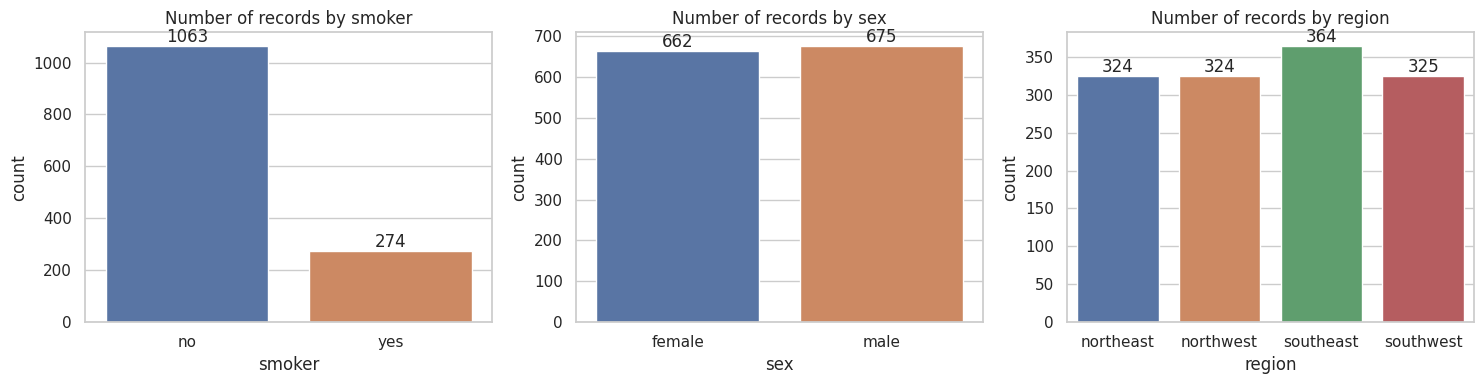

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["smoker", "sex", "region"]):
    sns.countplot(data=df, x=col, hue=col, ax=ax, legend=False)
    ax.set_title(f"Number of records by {col}")
    for container in ax.containers:
        ax.bar_label(container)
save_graph("category_count.png")

### 5.2 Feature distribution

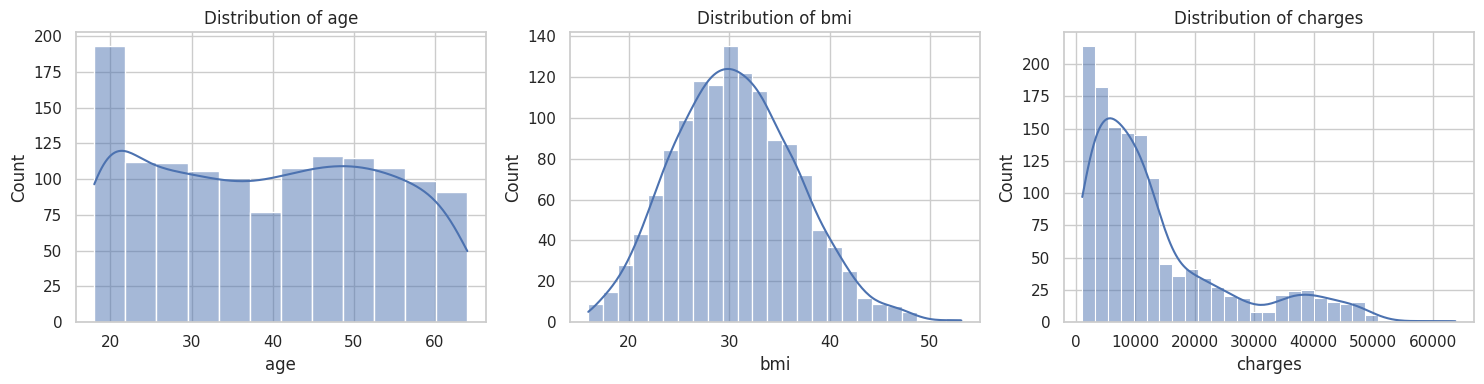

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["age", "bmi", "charges"]):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
save_graph("feature_distribution.png")

### 5.3 Outlier detection (box plots)

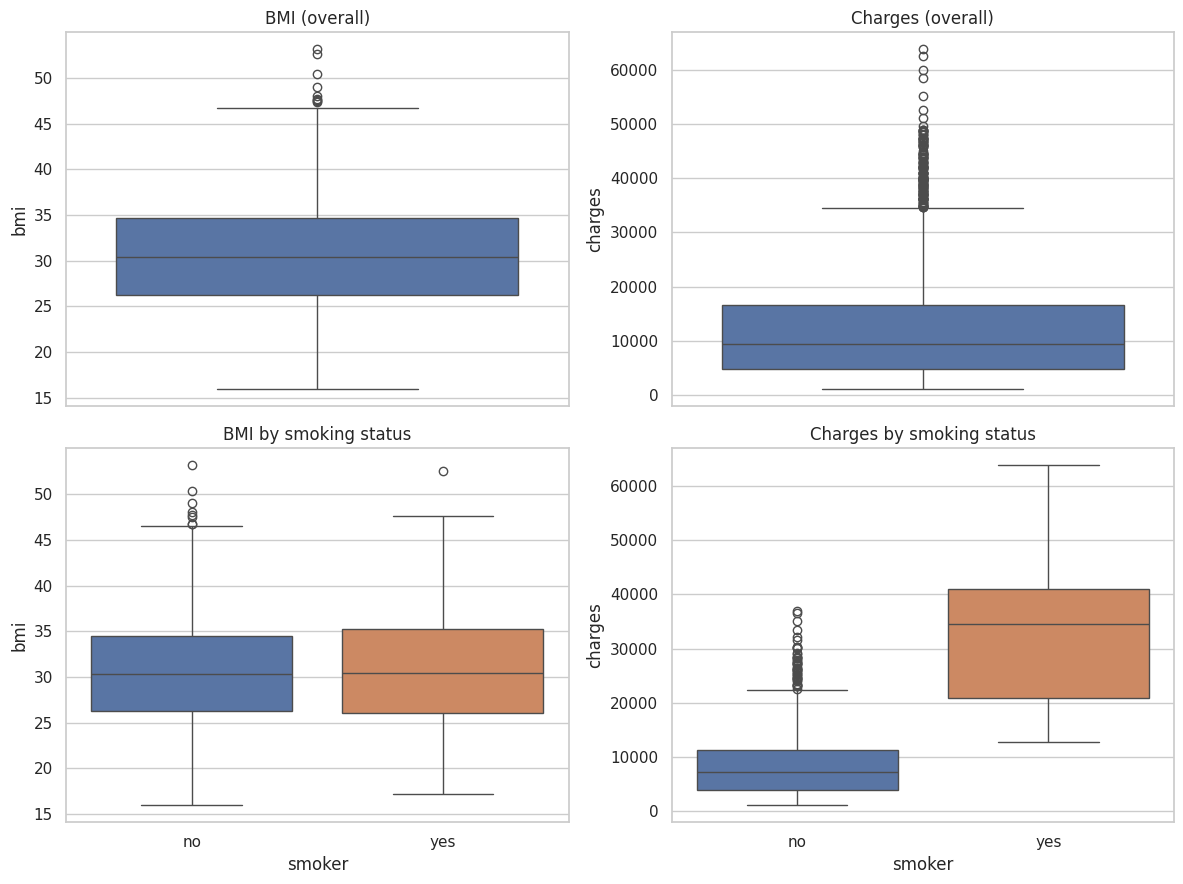

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.boxplot(y=df["bmi"], ax=axes[0, 0])
axes[0, 0].set_title("BMI (overall)")
sns.boxplot(y=df["charges"], ax=axes[0, 1])
axes[0, 1].set_title("Charges (overall)")
sns.boxplot(data=df, x="smoker", y="bmi", hue="smoker", ax=axes[1, 0], legend=False)
axes[1, 0].set_title("BMI by smoking status")
sns.boxplot(data=df, x="smoker", y="charges", hue="smoker", ax=axes[1, 1], legend=False)
axes[1, 1].set_title("Charges by smoking status")
save_graph("outlier_boxplot.png")

### 5.4 Age vs charges

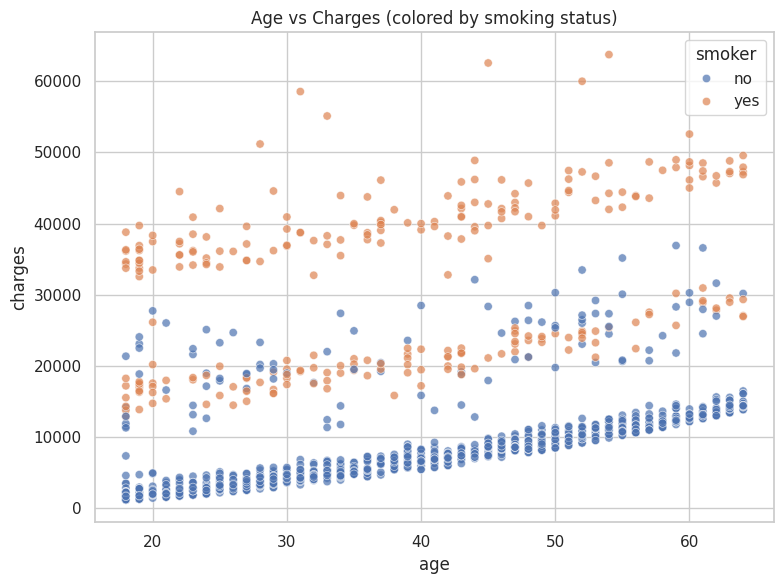

In [13]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.7)
plt.title("Age vs Charges (colored by smoking status)")
save_graph("scatter_age_charges.png")

### 5.5 BMI vs charges

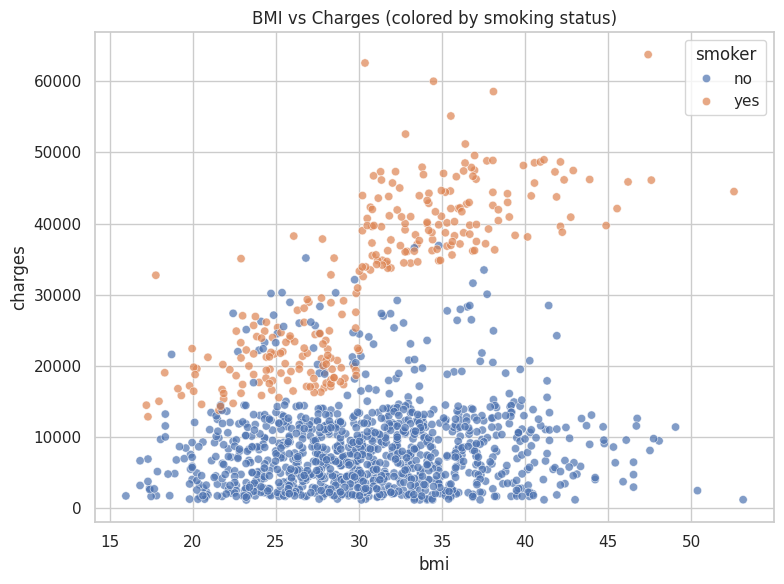

In [14]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.7)
plt.title("BMI vs Charges (colored by smoking status)")
save_graph("scatter_bmi_charges.png")

### 5.6 Average charges by group

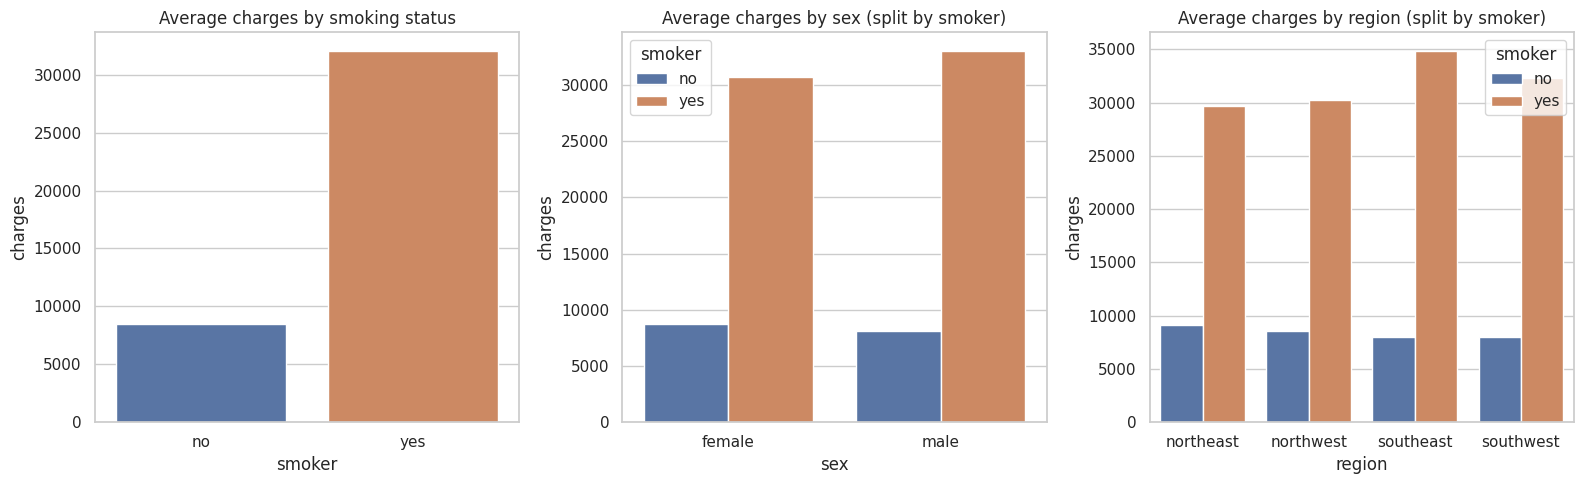

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.barplot(data=df, x="smoker", y="charges", hue="smoker", errorbar=None, ax=axes[0], legend=False)
axes[0].set_title("Average charges by smoking status")
sns.barplot(data=df, x="sex", y="charges", hue="smoker", errorbar=None, ax=axes[1])
axes[1].set_title("Average charges by sex (split by smoker)")
sns.barplot(data=df, x="region", y="charges", hue="smoker", errorbar=None, ax=axes[2])
axes[2].set_title("Average charges by region (split by smoker)")
save_graph("average_charges_by_group.png")

### 5.7 Pair plot

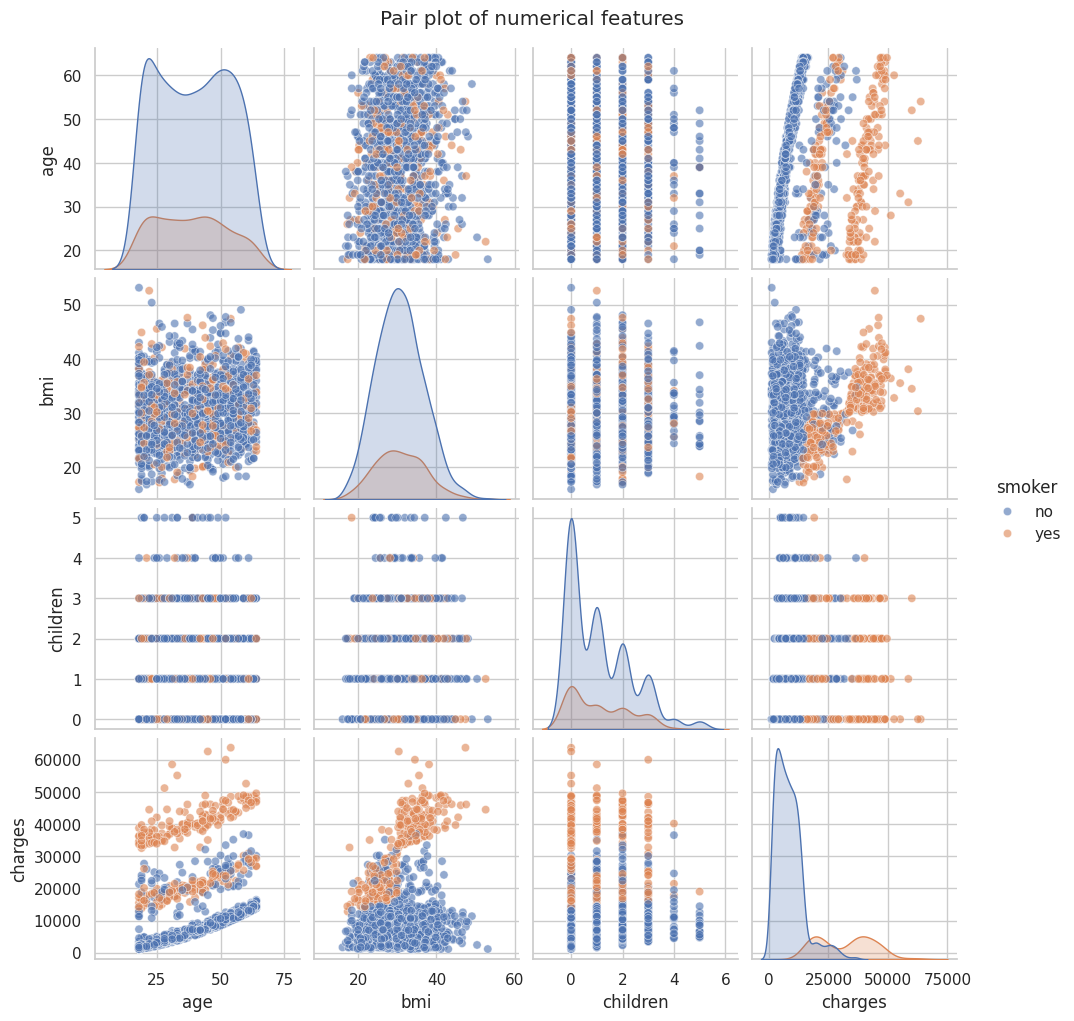

In [16]:
pair = sns.pairplot(df[["age", "bmi", "children", "charges", "smoker"]],
                    hue="smoker", diag_kind="kde", plot_kws={"alpha": 0.6})
pair.figure.suptitle("Pair plot of numerical features", y=1.02)
pair.figure.savefig("graphs/pairplot.png", dpi=120)
plt.show()

### 5.8 Correlation heatmap

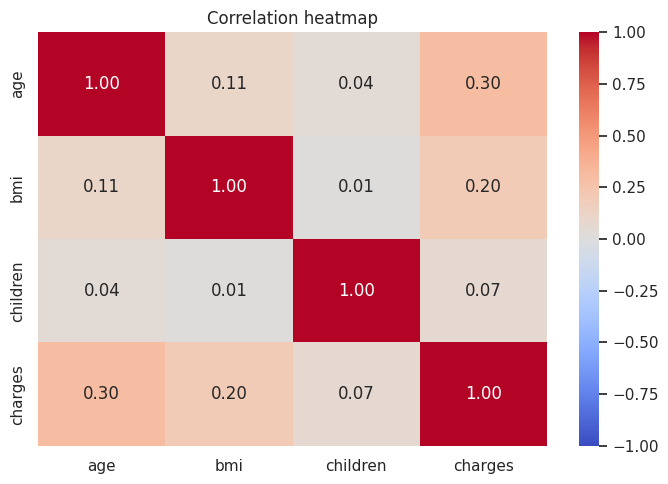

In [17]:
plt.figure(figsize=(7, 5))
corr = df[["age", "bmi", "children", "charges"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
save_graph("correlation_heatmap.png")

## Step 6: Insights report

In [18]:
smoker_avg = df.groupby("smoker", observed=True)["charges"].mean()
ratio = smoker_avg["yes"] / smoker_avg["no"]

df_num = df.copy()
df_num["smoker_code"] = (df_num["smoker"] == "yes").astype(int)
corr_with_charges = (
    df_num[["age", "bmi", "children", "smoker_code", "charges"]]
    .corr()["charges"].drop("charges").sort_values(ascending=False)
)

bmi_corr_smoker = df[df["smoker"] == "yes"][["bmi", "charges"]].corr().iloc[0, 1]
bmi_corr_nonsmoker = df[df["smoker"] == "no"][["bmi", "charges"]].corr().iloc[0, 1]

print("INSIGHTS REPORT: MEDICAL COST ANALYSIS")
print("-" * 40)
print(f"1. Dataset has {df.shape[0]} records and {df.shape[1]} columns.")
print(f"2. Missing values: {int(df.isnull().sum().sum())}. Duplicates removed: {dup_count}.")
print(f"3. Average charges: smokers = ${smoker_avg['yes']:,.2f}, non-smokers = ${smoker_avg['no']:,.2f}.")
print(f"   Smokers pay about {ratio:.1f} times more on average.")
print("4. Correlation of each feature with charges:")
for name, value in corr_with_charges.items():
    print(f"     {name:12s} {value:6.2f}")
print(f"   Strongest factor: {corr_with_charges.abs().idxmax()}")
print(f"5. BMI vs charges correlation: smokers = {bmi_corr_smoker:.2f}, non-smokers = {bmi_corr_nonsmoker:.2f}.")
print(f"6. Charges are right skewed (skewness = {df['charges'].skew():.2f}).")
print("7. Outliers (IQR method): " + ", ".join(f"{k}={v}" for k, v in outlier_summary.items()))

INSIGHTS REPORT: MEDICAL COST ANALYSIS
----------------------------------------
1. Dataset has 1337 records and 7 columns.
2. Missing values: 0. Duplicates removed: 1.
3. Average charges: smokers = $32,050.23, non-smokers = $8,440.66.
   Smokers pay about 3.8 times more on average.
4. Correlation of each feature with charges:
     smoker_code    0.79
     age            0.30
     bmi            0.20
     children       0.07
   Strongest factor: smoker_code
5. BMI vs charges correlation: smokers = 0.81, non-smokers = 0.08.
6. Charges are right skewed (skewness = 1.52).
7. Outliers (IQR method): age=0, bmi=9, children=0, charges=139


## Step 7: Conclusion
Write your own conclusion here after reading the output above. Mention which factor affects charges the most, how smokers compare with non-smokers, what the BMI plot showed, and which columns had outliers.

## Step 8 (optional): Download all graphs
Run this to get every graph as a zip file for your GitHub repo.

In [19]:
import shutil
shutil.make_archive("graphs", "zip", "graphs")
from google.colab import files
files.download("graphs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>